## Les bibliothèques

In [266]:
import glob
import nibabel as nib
import matplotlib.pyplot as plt
import os, numpy as np, pandas as pd
from scipy.ndimage import gaussian_filter
from skimage.filters import threshold_otsu
from skimage.segmentation import morphological_chan_vese, disk_level_set
from sklearn.cluster import KMeans

## Cree des foldes

In [265]:
base_dir = "Documents/ACDC/"
dataset_dir = os.path.join(base_dir, "dataset")

nouveaux_dossiers = [
    "pretraitement",
    "segmentation",
    "posttraitement",
    "unet",
    "mesures"]
for nom in nouveaux_dossiers:
    os.makedirs(os.path.join(base_dir, nom), exist_ok=True)

## lire des information

In [243]:
p = patient_folders[0] # premier patient
patient_name = os.path.basename(p)

info = read_info(p)
print(f"informations pour {patient_name} ")
print(info)

# 4. Charger l'image 4D associée
nii_files = glob.glob(os.path.join(p, "*_4d.nii.gz")) 
if nii_files:
    img_path = nii_files[0]
    img = nib.load(img_path)
    data = img.get_fdata()
    print("chemin :", img_path)
    print("dimensions :", data.shape)
    print(f"Phase ED (Fin Diastole):instant {info.get('ED')}") ## l'instant de la phase ED (Fin de diastole) depuis Info.cfg
    print(f"Phase ES (Fin Systole):instant {info.get('ES')}") ## l'instant de la phase ES (Fin de systole)  depuis Info.cfg

informations pour patient002 
{'ED': ' 1', 'ES': ' 12', 'Group': ' DCM', 'Height': ' 160.0', 'NbFrame': ' 30', 'Weight': ' 70.0'}
chemin : Documents/ACDC/dataset\patient002\patient002_4d.nii.gz
dimensions : (232, 256, 10, 30)
Phase ED (Fin Diastole):instant  1
Phase ES (Fin Systole):instant  12


- ED = 1 : quand le cœur est rempli de sang, juste avant de se contracter
- ES = 12 : quand le cœur vient de se contracter et a expulsé du sang
- Group = DCM : le patient a une cardiomyopathie dilatée
- Height = 160 cm : la taille du patient est de 1,60 m
- Weight = 70 kg : le patient pèse 70 kg
- NbFrame = 30 images pour un cycle cardiaque complet
les dimensions (232, 256, 10, 30) 4D :
- 232 : largeur de l'image en pixels.
- 256 : hauteur de l'image en pixels.
- 10 : nombre de coupes du cœur
- 30 : nombre de phases du cycle cardiaque

In [244]:
pid = os.path.basename(p)
ed = int(info["ED"])

gt_nii  = nib.load(os.path.join(p, f"{pid}_frame{ed:02d}_gt.nii.gz"))
gt  = gt_nii.get_fdata()               # Masque de segmentation

print("Labels dans la vérité terrain (gt) :", np.unique(gt))

Labels dans la vérité terrain (gt) : [0. 1. 2. 3.]


- Label 0 : arrière-plan
- Label 1 : cavité du ventricule droit RV
- Label 2 : myocarde ou le muscle du cœur
- Label 3 : cavité du ventricule gauche LV

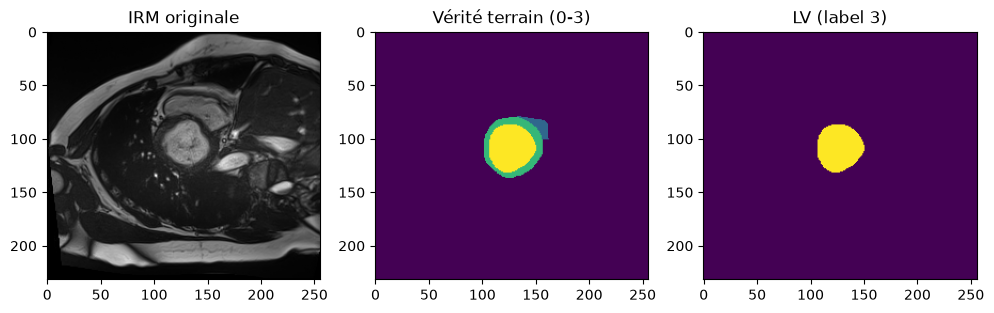

In [258]:
import matplotlib.pyplot as plt
import numpy as np
img_data = img.get_fdata()
gt_data = gt if isinstance(gt, np.ndarray) else gt.get_fdata()
time_idx = 0
slice_idx = 5  

img_slice = img_data[:, :, time_idx, slice_idx]  # 4D
gt_slice = gt_data[:, :, slice_idx]              # 3D

fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(img_slice, cmap="gray")
ax[0].set_title("IRM originale")
ax[1].imshow(gt_slice)
ax[1].set_title("Vérité terrain (0-3)")
ax[2].imshow(gt_slice == 3)
ax[2].set_title("LV (label 3)")
plt.show()

# Segmentation et Pre_traitement

In [267]:
dataset_dir = os.path.join(base_dir, "dataset")
out_dir = os.path.join(base_dir, "segmentation")
os.makedirs(out_dir, exist_ok=True)

patient_folders = sorted(glob.glob(os.path.join(dataset_dir, "patient*")))[:4]
print("patients :", [os.path.basename(p) for p in patient_folders])

def read_info(p): #transformer en dictionnaire le fichier Info.cfg
    return dict(line.strip().split(":", 1) for line in open(os.path.join(p, "Info.cfg")) if ":" in line)

def dice(a, b): # calculer le coef de Dice (mesure de similarité)
    return 2 * np.logical_and(a, b).sum() / (a.sum() + b.sum() + 1e-8)

patients : []


==> Le **Dice** mesure la ressemblance entre la segmentation prédite et la vérité terrain (GT). varie entre 0 et 1 : 

1 signifie une segmentation parfaite

0 signifie qu'il n'y a aucun pixel commun entre les deux segmentations

Plus le Dice est proche de 1, meilleure est la segmentation

In [261]:
def preparer(image):
    image_lisse = gaussian_filter(image.astype(np.float32), sigma=1.5)
    H, W = image_lisse.shape
    zone_centre = np.zeros((H, W), dtype=bool)
    zone_centre[H//4:3*H//4, W//4:3*W//4] = True  # Garde uniquement le carré du milieu
    return image_lisse, zone_centre

#méthode 1 : Otsu
def seg_otsu(image):
    image_lisse, zone_centre = preparer(image)
    seuil = threshold_otsu(image_lisse[zone_centre])
    return (image_lisse > seuil) & zone_centre

# méthode 2 : K-Means
def seg_kmeans(image, k=4):
    image_lisse, zone_centre = preparer(image)
    kmeans_model = KMeans(n_clusters=k, n_init=3, random_state=0).fit(image_lisse[zone_centre].reshape(-1, 1))
    cluster_clair = np.argmax(kmeans_model.cluster_centers_.ravel())
    
    masque = np.zeros(image_lisse.shape, dtype=bool)
    masque[zone_centre] = (kmeans_model.labels_ == cluster_clair)
    return masque

#méthode 3 : Contours Actifs
def seg_contour_actif(image):
    image_lisse, zone_centre = preparer(image)
    image_lisse = (image_lisse - image_lisse.min()) / (image_lisse.max() - image_lisse.min() + 1e-8)
    
    H, W = image_lisse.shape
    cercle_initial = disk_level_set(image_lisse.shape, center=(H//2, W//2), radius=min(H, W)//8)
    contour_resultat = morphological_chan_vese(image_lisse, num_iter=60, init_level_set=cercle_initial, smoothing=2).astype(bool)
    
    if contour_resultat.any() and (~contour_resultat).any() and image_lisse[contour_resultat].mean() < image_lisse[~contour_resultat].mean():
        contour_resultat = ~contour_resultat
        
    return contour_resultat & zone_centre

METHODES = {
    "otsu": seg_otsu, 
    "kmeans": seg_kmeans, 
    "contour_actif": seg_contour_actif
}

## Teste pour 4 patients :

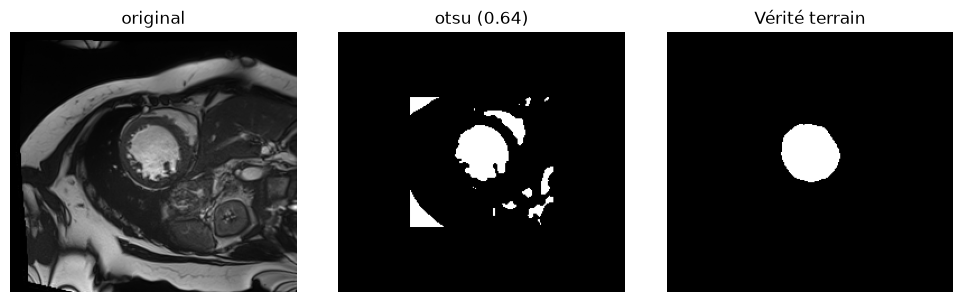

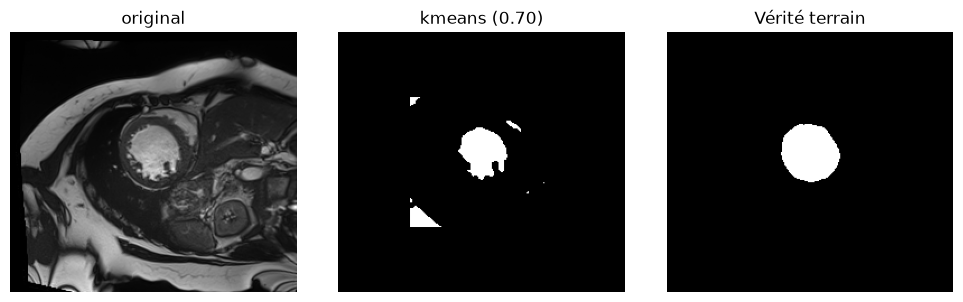

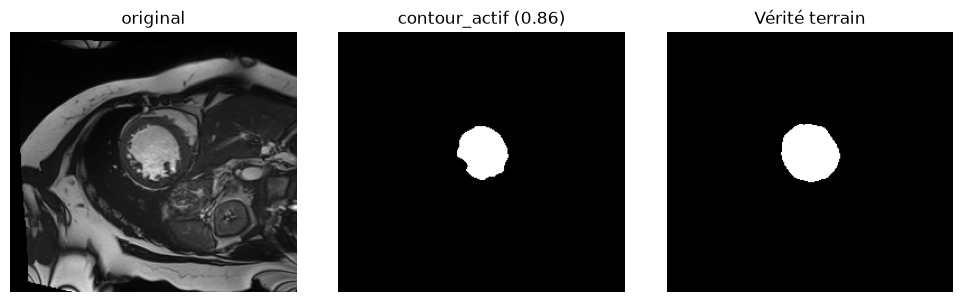

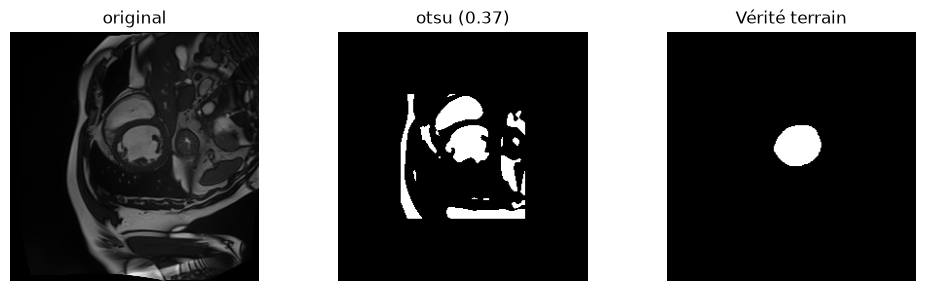

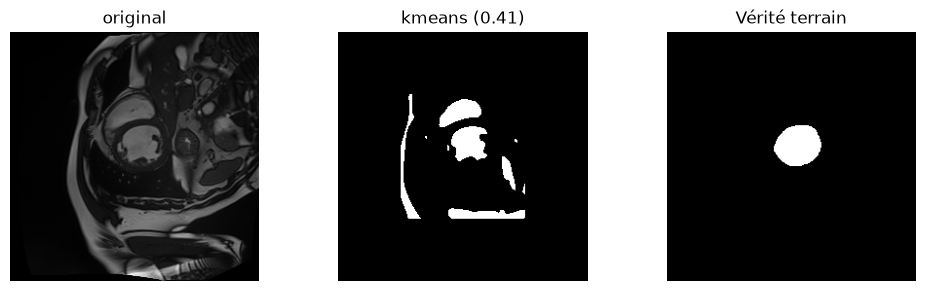

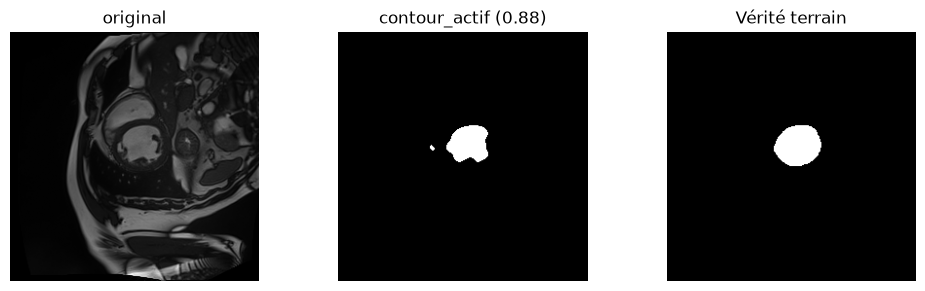

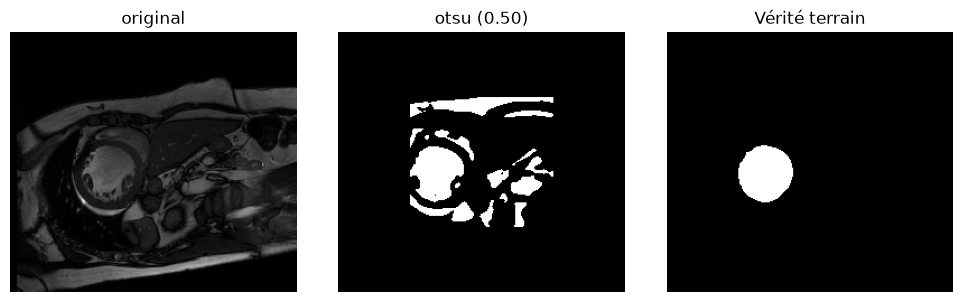

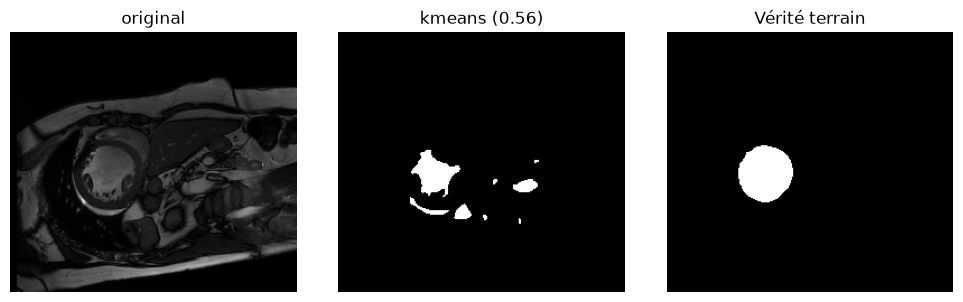

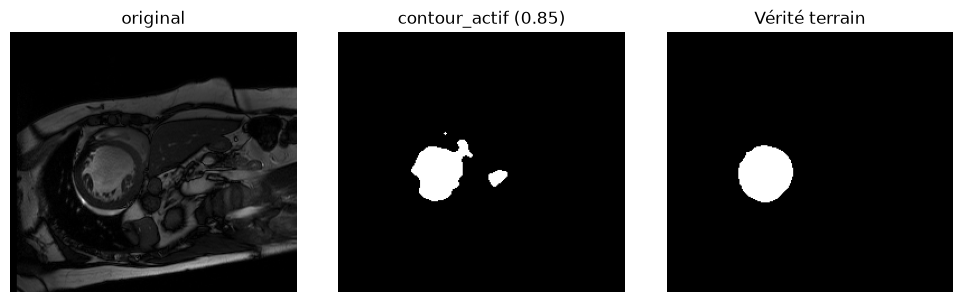

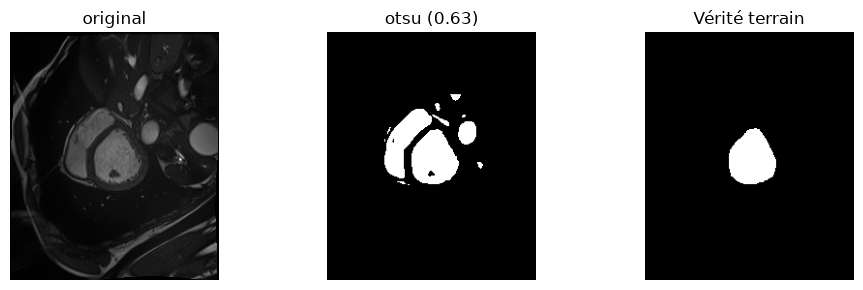

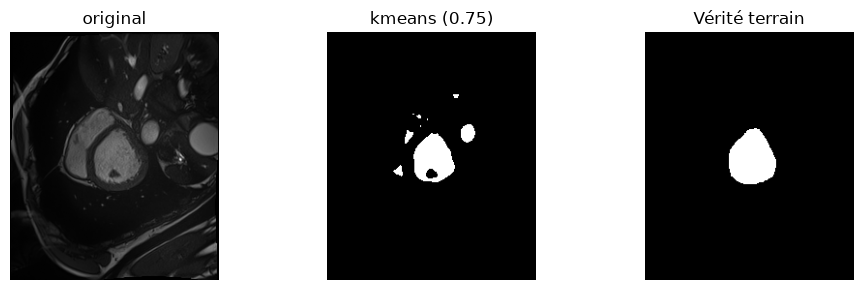

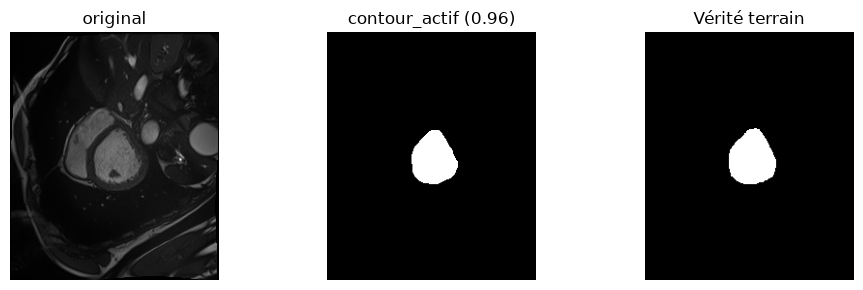

In [262]:
resultats = []

for p in patient_folders:
    pid = os.path.basename(p)
    ed = int(read_info(p)["ED"])
    
    # Chargement image et masque ED
    img = nib.load(os.path.join(p, f"{pid}_frame{ed:02d}.nii.gz")).get_fdata()
    gt = nib.load(os.path.join(p, f"{pid}_frame{ed:02d}_gt.nii.gz")).get_fdata() == 3

    slices = [z for z in range(img.shape[2]) if gt[:, :, z].any()]
    if not slices: continue
    z_ref = max(slices, key=lambda z: gt[:, :, z].sum())

    for nom, func in METHODES.items():
        os.makedirs(os.path.join(out_dir, nom), exist_ok=True)
        
        # Calcul des scores Dice pour toutes les coupes
        dices = [dice(func(img[:, :, z]), gt[:, :, z]) for z in slices]
        
        # Segmentation et score pour la coupe de référence
        m_ref = func(img[:, :, z_ref])
        d_ref = dice(m_ref, gt[:, :, z_ref])
        resultats.append((pid, nom, np.mean(dices), d_ref))

        # Affichage et sauvegarde
        fig, ax = plt.subplots(1, 3, figsize=(10, 3))
        ax[0].imshow(img[:, :, z_ref], cmap="gray"); ax[0].set_title("original")
        ax[1].imshow(m_ref, cmap="gray"); ax[1].set_title(f"{nom} ({d_ref:.2f})")
        ax[2].imshow(gt[:, :, z_ref], cmap="gray"); ax[2].set_title("Vérité terrain")
        for a in ax: a.axis("off")
        
        plt.tight_layout()
        fig.savefig(os.path.join(out_dir, nom, f"{pid}_ED.png"), dpi=100)
        plt.show()

In [263]:
df = pd.DataFrame(resultats, columns=["patient", "methode", "dice_moyen", "dice_slice_affichee"])

print("Dice pour cahque patient :")
print(df.pivot(index="patient", columns="methode", values="dice_moyen").round(2))

moy = df.groupby("methode")["dice_moyen"].mean().sort_values(ascending=False)
print("\n la moyenne sur les 4 patients :")
print(moy.round(2))

df.to_csv(os.path.join(out_dir, "comparaison_dice.csv"), index=False)
print("\n→ meilleur Dice :", moy.index[0])

Dice pour cahque patient :
methode     contour_actif  kmeans  otsu
patient                                
patient002           0.70    0.49  0.42
patient003           0.65    0.34  0.30
patient004           0.56    0.29  0.36
patient005           0.70    0.55  0.54

 la moyenne sur les 4 patients :
methode
contour_actif    0.65
kmeans           0.41
otsu             0.40
Name: dice_moyen, dtype: float64

→ meilleur Dice : contour_actif


# Tout les patients : 

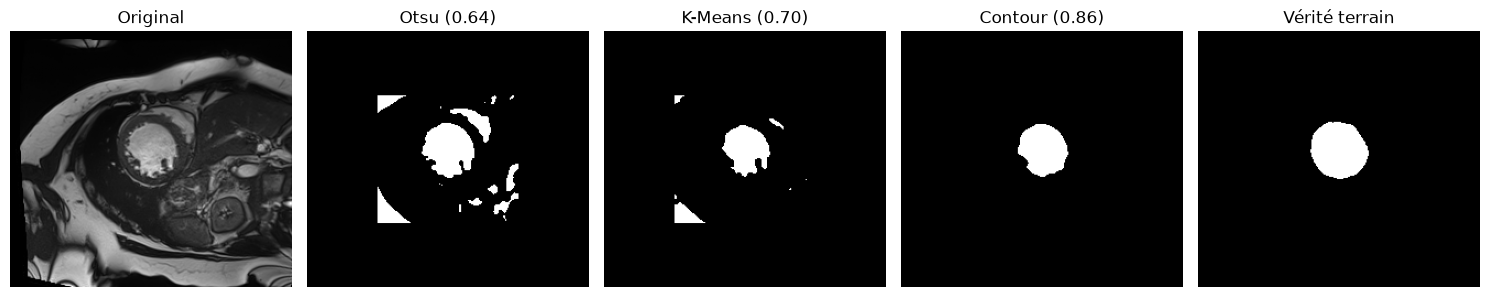

Patient patient002 terminé


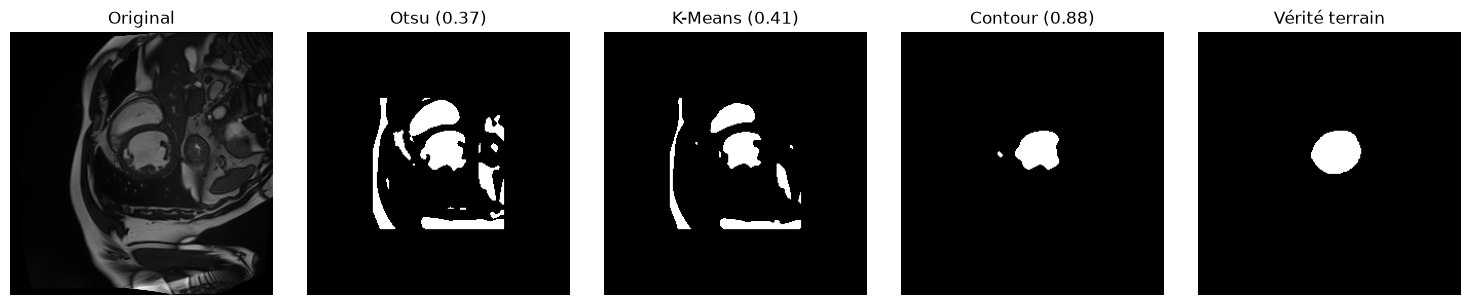

Patient patient003 terminé


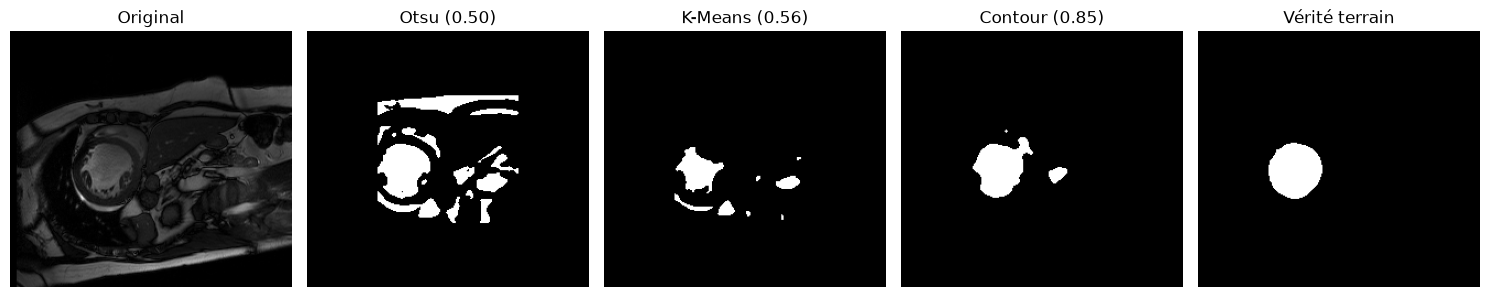

Patient patient004 terminé
Patient patient005 terminé


In [264]:
comp_dir = os.path.join(out_dir, "comparaison")
os.makedirs(comp_dir, exist_ok=True) 

resultats = []
N_AFFICHER = 3

for i, p in enumerate(patient_folders):
    try:
        pid = os.path.basename(p)
        ed = int(read_info(p)["ED"])
        
        img = nib.load(os.path.join(p, f"{pid}_frame{ed:02d}.nii.gz")).get_fdata()
        gt = nib.load(os.path.join(p, f"{pid}_frame{ed:02d}_gt.nii.gz")).get_fdata() == 3

        slices = [z for z in range(img.shape[2]) if gt[:, :, z].any()]
        if not slices: continue
        z_ref = max(slices, key=lambda z: gt[:, :, z].sum())

        masques_ref = {}
        dices_ref = {}

        for nom, func in METHODES.items():
            dossier_methode = os.path.join(out_dir, nom)
            os.makedirs(dossier_methode, exist_ok=True)
            
            dices = [dice(func(img[:, :, z]), gt[:, :, z]) for z in slices]
            m_ref = func(img[:, :, z_ref])
            d_ref = dice(m_ref, gt[:, :, z_ref])
            
            masques_ref[nom] = m_ref
            dices_ref[nom] = d_ref
            resultats.append((pid, nom, np.mean(dices), d_ref))

            fig_sep, ax_sep = plt.subplots(1, 3, figsize=(10, 3))
            ax_sep[0].imshow(img[:, :, z_ref], cmap="gray"); ax_sep[0].set_title("original")
            ax_sep[1].imshow(m_ref, cmap="gray"); ax_sep[1].set_title(f"{nom} ({d_ref:.2f})")
            ax_sep[2].imshow(gt[:, :, z_ref], cmap="gray"); ax_sep[2].set_title("Vérité terrain")
            for a in ax_sep: a.axis("off")
            plt.tight_layout()
            fig_sep.savefig(os.path.join(dossier_methode, f"{pid}_ED.png"), dpi=100)
            plt.close(fig_sep)

        fig_comp, ax_comp = plt.subplots(1, 5, figsize=(15, 3))
        ax_comp[0].imshow(img[:, :, z_ref], cmap="gray"); ax_comp[0].set_title("Original")
        ax_comp[1].imshow(masques_ref["otsu"], cmap="gray"); ax_comp[1].set_title(f"Otsu ({dices_ref['otsu']:.2f})")
        ax_comp[2].imshow(masques_ref["kmeans"], cmap="gray"); ax_comp[2].set_title(f"K-Means ({dices_ref['kmeans']:.2f})")
        ax_comp[3].imshow(masques_ref["contour_actif"], cmap="gray"); ax_comp[3].set_title(f"Contour ({dices_ref['contour_actif']:.2f})")
        ax_comp[4].imshow(gt[:, :, z_ref], cmap="gray"); ax_comp[4].set_title("Vérité terrain")
        
        for a in ax_comp: a.axis("off")
        plt.tight_layout()
        fig_comp.savefig(os.path.join(comp_dir, f"{pid}_comparaison.png"), dpi=100)
        
        if i < N_AFFICHER:
            plt.show()
        plt.close(fig_comp)

        print(f"Patient {pid} terminé")

    except Exception as e:
        print(f"erreur patient {pid} : {e}")

In [113]:
dossier = os.path.join(out_dir, "contour_actif")
os.makedirs(dossier, exist_ok=True)

phase = "ES"
for p in patient_folders:
    try:
        pid = os.path.basename(p)
        n = int(read_info(p)[phase])

        img = nib.load(os.path.join(p, f"{pid}_frame{n:02d}.nii.gz")).get_fdata()
        gt  = nib.load(os.path.join(p, f"{pid}_frame{n:02d}_gt.nii.gz")).get_fdata() == 3

        slices = [z for z in range(img.shape[2]) if gt[:, :, z].any()]
        if not slices:
            continue
        z_ref = max(slices, key=lambda z: gt[:, :, z].sum())

        m_ref = seg_contour_actif(img[:, :, z_ref])
        d_ref = dice(m_ref, gt[:, :, z_ref])

        fig, ax = plt.subplots(1, 3, figsize=(10, 3))
        ax[0].imshow(img[:, :, z_ref], cmap="gray"); ax[0].set_title("original")
        ax[1].imshow(m_ref, cmap="gray");            ax[1].set_title(f"contour_actif ({d_ref:.2f})")
        ax[2].imshow(gt[:, :, z_ref], cmap="gray");  ax[2].set_title("Vérité terrain")
        for a in ax: a.axis("off")
        plt.tight_layout()
        fig.savefig(os.path.join(dossier, f"{pid}_{phase}.png"), dpi=100)
        plt.close(fig)

        print(f"{pid} {phase}")
    except Exception as e:
        print(f"erreur patient {pid} : {e}")

patient002 ES
patient003 ES
patient004 ES
patient005 ES
patient006 ES
patient007 ES
patient008 ES
patient009 ES
patient010 ES
patient011 ES
patient012 ES
patient013 ES
patient014 ES
patient015 ES
patient016 ES
patient017 ES
patient018 ES
patient019 ES
patient020 ES
patient021 ES
patient022 ES
patient023 ES
patient024 ES
patient025 ES
patient026 ES
patient027 ES
patient028 ES
patient029 ES
patient030 ES
patient031 ES
patient032 ES
patient033 ES
patient034 ES
patient035 ES
patient036 ES
patient037 ES
patient038 ES
patient039 ES
patient040 ES
patient041 ES
patient042 ES
patient043 ES
patient044 ES
patient045 ES
patient046 ES
patient047 ES
patient048 ES
patient049 ES
patient050 ES
patient051 ES
patient052 ES
patient053 ES
patient054 ES
patient055 ES
patient056 ES
patient057 ES
patient058 ES
patient059 ES
patient060 ES
patient061 ES
patient062 ES
patient063 ES
patient064 ES
patient065 ES
patient066 ES
patient067 ES
patient068 ES
patient069 ES
patient070 ES
patient071 ES
patient072 ES
patien

In [48]:
df = pd.DataFrame(resultats, columns=["patient", "methode", "dice_moyen", "dice_slice_affichee"])
df.to_csv(os.path.join(out_dir, "comparaison_dice.csv"), index=False) #crée un CSV pour stocker des données sous forme de tableau

resume = df.groupby("methode")["dice_moyen"].agg(moyenne="mean", mediane="median")
resume = resume.sort_values("moyenne", ascending=False).round(3)
print(resume)
print("\n→ meilleur Dice moyen :", resume.index[0])

               moyenne  mediane
methode                        
contour_actif    0.514    0.520
kmeans           0.381    0.397
otsu             0.326    0.316

→ meilleur Dice moyen : contour_actif


### ==> le contour actif obtient les meilleures performances avec un Dice moyen de 0,514 (et une médiane de 0,520), devançant nettement K-Means (0,381) et Otsu (0,326)

# Poste_traitemnt

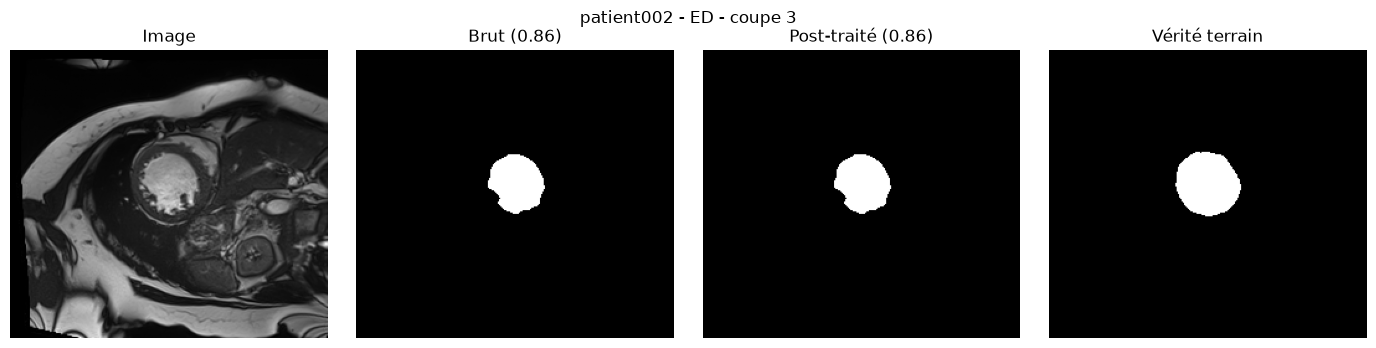

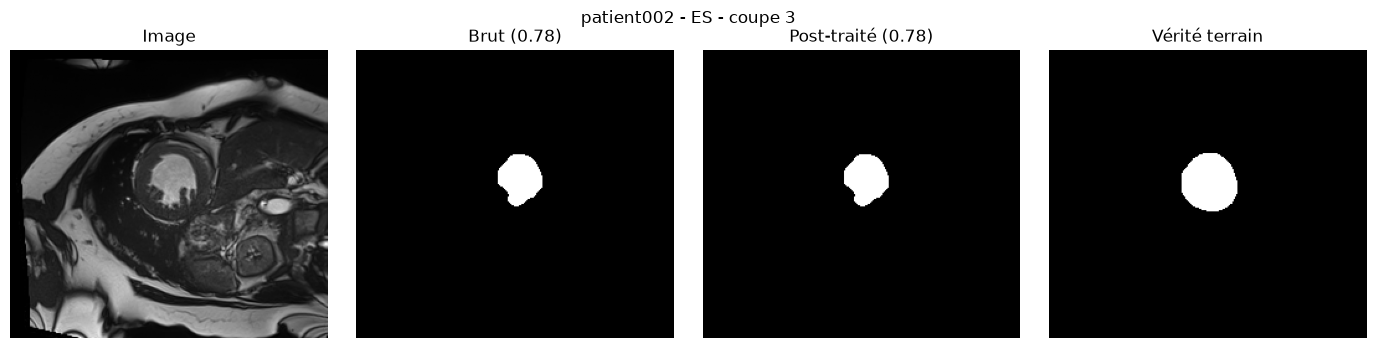

patient002 


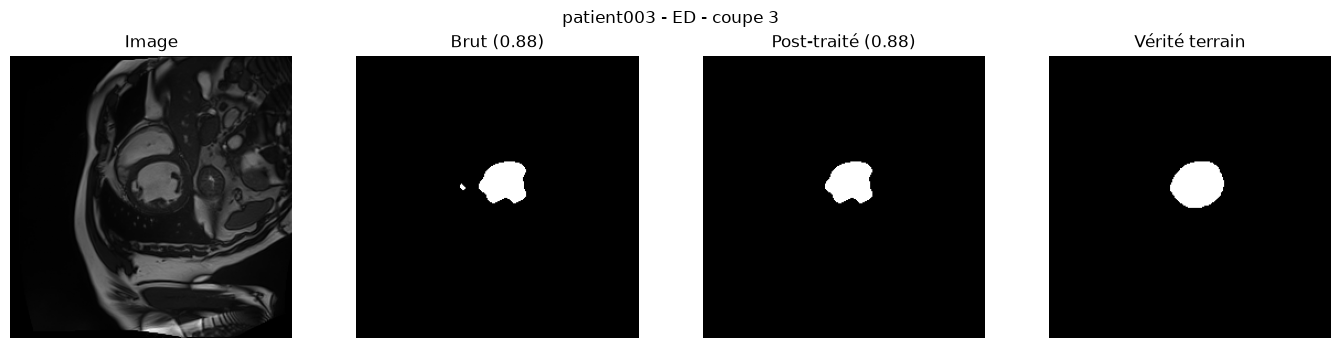

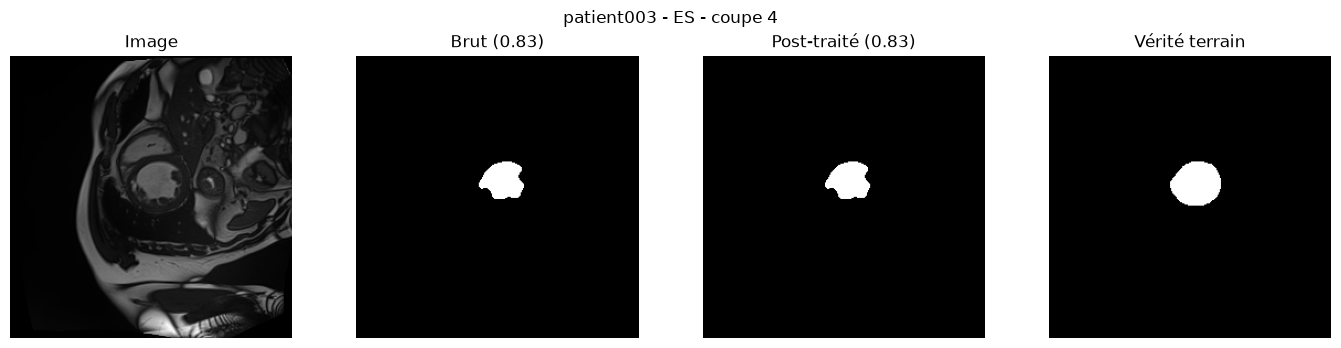

patient003 


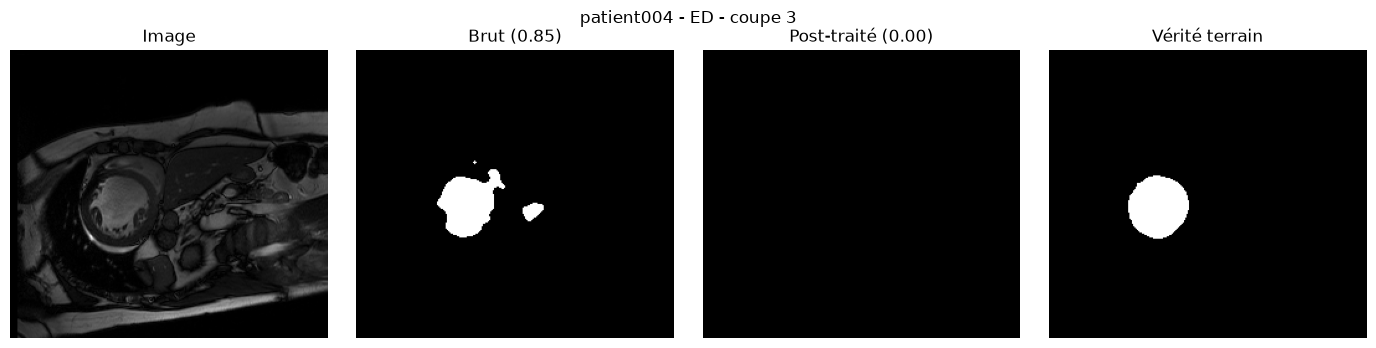

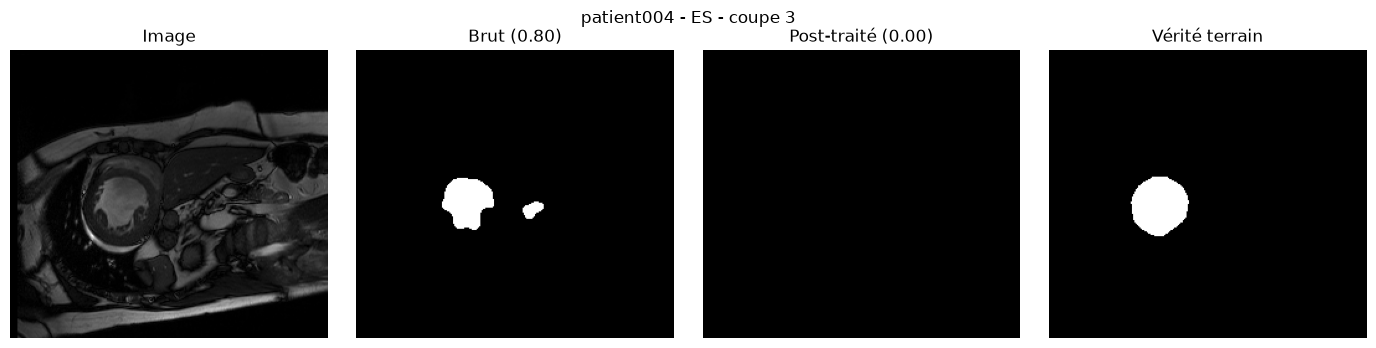

patient004 


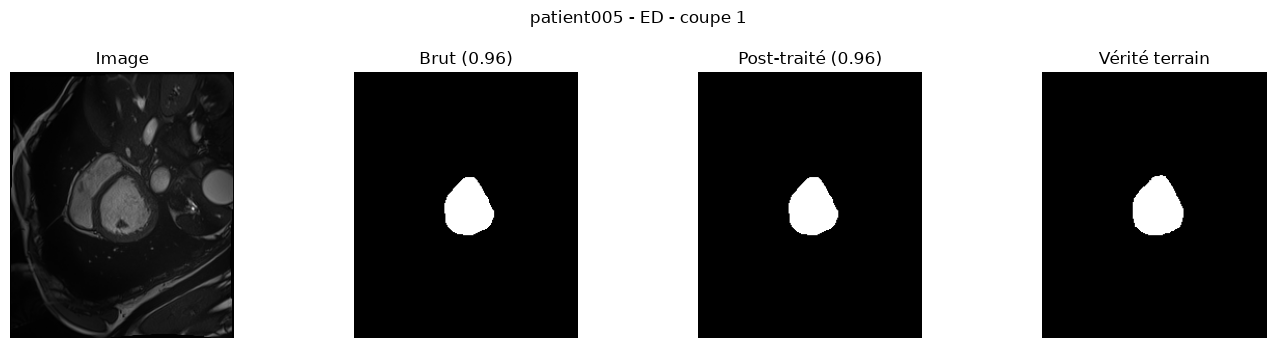

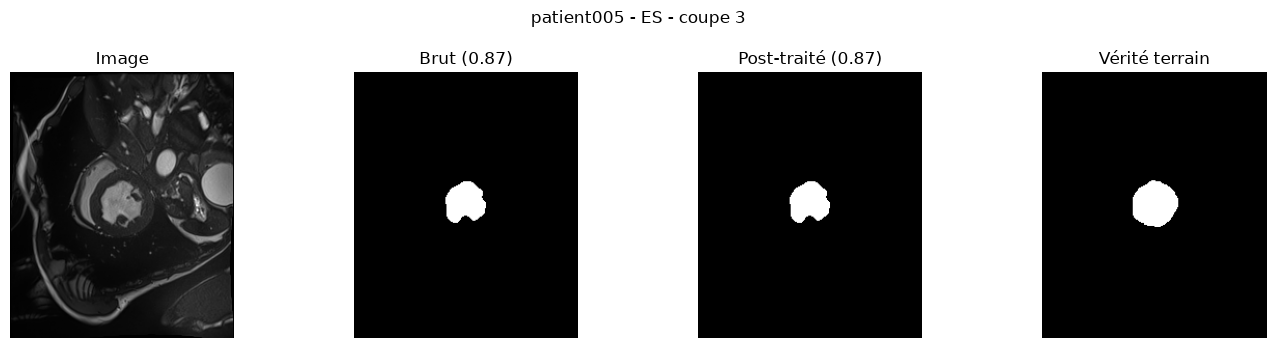

patient005 
patient006 
patient007 
patient008 
patient009 
patient010 
patient011 
patient012 
patient013 
patient014 
patient015 
patient016 
patient017 
patient018 
patient019 
patient020 
patient021 
patient022 
patient023 
patient024 
patient025 
patient026 
patient027 
patient028 
patient029 
patient030 
patient031 
patient032 
patient033 
patient034 
patient035 
patient036 
patient037 
patient038 
patient039 
patient040 
patient041 
patient042 
patient043 
patient044 
patient045 
patient046 
patient047 
patient048 
patient049 
patient050 
patient051 
patient052 
patient053 
patient054 
patient055 
patient056 
patient057 
patient058 
patient059 
patient060 
patient061 
patient062 
patient063 
patient064 
patient065 
patient066 
patient067 
patient068 
patient069 
patient070 
patient071 
patient072 
patient073 
patient074 
patient075 
patient076 
patient077 
patient078 
patient079 
patient080 
patient081 
patient082 
patient083 
patient084 
patient085 
patient086 
patient087 
pati

In [117]:
from scipy import ndimage as ndi
from skimage.measure import label, regionprops

pt_dir = os.path.join(base_dir, "posttraitement")
os.makedirs(pt_dir, exist_ok=True)
N_AFFICHER = 4      # nb de patients affichés (ED et ES)

def post_traitement(m):
    """remplit les trous, garde la région (50-4000 px) la plus proche du centre"""
    m = ndi.binary_fill_holes(m)
    lab = label(m)
    H, W = m.shape
    regions = [r for r in regionprops(lab) if 50 <= r.area <= 4000]
    if not regions:
        return np.zeros(m.shape, np.uint8)
    r = min(regions, key=lambda r: np.hypot(r.centroid[0] - H/2, r.centroid[1] - W/2))
    return (lab == r.label).astype(np.uint8)
def pt_3d(vol):
    lab = label(vol, connectivity=3)
    if lab.max() == 0:
        return vol
    tailles = np.bincount(lab.ravel()); tailles[0] = 0
    return (lab == tailles.argmax()).astype(np.uint8)
    

res_pt = []
for i, p in enumerate(patient_folders):         
    pid = os.path.basename(p)
    info = read_info(p)

    for phase in ["ED", "ES"]:
        n = int(info[phase])
        gt_nii = nib.load(os.path.join(p, f"{pid}_frame{n:02d}_gt.nii.gz"))
        img    = nib.load(os.path.join(p, f"{pid}_frame{n:02d}.nii.gz")).get_fdata()
        gt     = gt_nii.get_fdata() == 3
        slices = [z for z in range(gt.shape[2]) if gt[:, :, z].any()]
        if not slices:
            continue

        # contour actif puis post-traitement
        brut   = np.stack([seg_contour_actif(img[:, :, z]) for z in range(img.shape[2])], axis=2)
        propre = np.stack([post_traitement(brut[:, :, z]) for z in range(brut.shape[2])], axis=2)
        propre = pt_3d(propre)
        np.save(os.path.join(pt_dir, f"{pid}_{phase}.npy"), propre)

        # dice et erreur de volume
        d_avant = np.mean([dice(brut[:, :, z],   gt[:, :, z]) for z in slices])
        d_apres = np.mean([dice(propre[:, :, z], gt[:, :, z]) for z in slices])
        v_gt = volume_ml(gt, gt_nii)
        v_brut, v_propre = volume_ml(brut, gt_nii), volume_ml(propre, gt_nii)
        res_pt.append((pid, phase, d_avant, d_apres,
                       abs(v_brut - v_gt) / v_gt * 100,
                       abs(v_propre - v_gt) / v_gt * 100,
                       v_gt, v_propre))

        # affichage des N premiers patients (ED et ES)
        if i < N_AFFICHER:
            z = max(slices, key=lambda z: gt[:, :, z].sum())
            fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
            for a, (im, t) in zip(ax, [(img[:, :, z], "Image"),
                                       (brut[:, :, z],   f"Brut ({dice(brut[:, :, z], gt[:, :, z]):.2f})"),
                                       (propre[:, :, z], f"Post-traité ({dice(propre[:, :, z], gt[:, :, z]):.2f})"),
                                       (gt[:, :, z], "Vérité terrain")]):
                a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
            fig.suptitle(f"{pid} - {phase} - coupe {z}")
            plt.tight_layout(); plt.show()

    print(f"{pid} ")


In [118]:
def volume_ml(masque, nii):
    """Volume d'un masque 3D en mL"""
    return masque.sum() * np.prod(nii.header.get_zooms()[:3]) / 1000

df = pd.DataFrame(res_pt, columns=["patient", "phase", "dice_avant", "dice_apres",
                                   "err_avant_%", "err_apres_%", "vol_GT_mL", "vol_propre_mL"])
df.to_csv(os.path.join(pt_dir, "resume_post_traitement.csv"), index=False)


print(df.groupby("phase")[["dice_avant", "dice_apres"]].mean().round(3))

print("\n erreur de volume")
print(df.groupby("phase")[["err_avant_%", "err_apres_%"]].median().round(1))
print(f"Avant : {df['err_avant_%'].median():.0f}% | Après : {df['err_apres_%'].median():.0f}%")

       dice_avant  dice_apres
phase                        
ED          0.516       0.495
ES          0.328       0.303

 erreur de volume
       err_avant_%  err_apres_%
phase                          
ED           188.2         57.9
ES           675.8        118.7
Avant : 302% | Après : 84%


###  ==> Le post-traitement permet d'éliminer bruit de fond et artéfacts présents dans la segmentation brute ici le dice est un peut diinier qui est logique puisque contour actif donne un seu cercle de masque  puis qand applique un poste_traitement si le reesultat de pste traitement sera unn petit cercle une fois appliquer le poste traiteemtn en elimine tout or il sera meilleur pour Otsu car il donne bc de masque et le posttraitement elimine c'est cercle qui on pas LV, réduisant l'erreur médiane de volume de 302% à 84%. bien que le score de Dice reste stable (autour de 0.45 - 0.50)

# Post_traitement Otsu : 

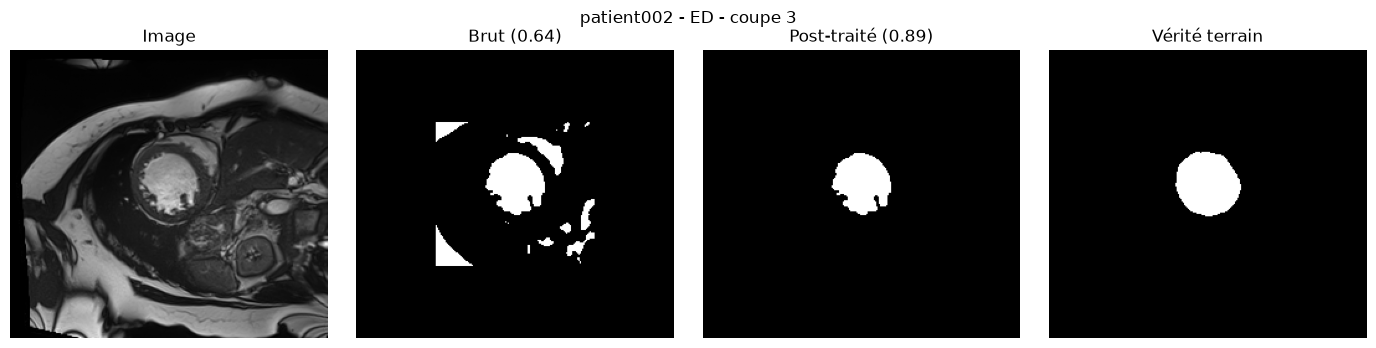

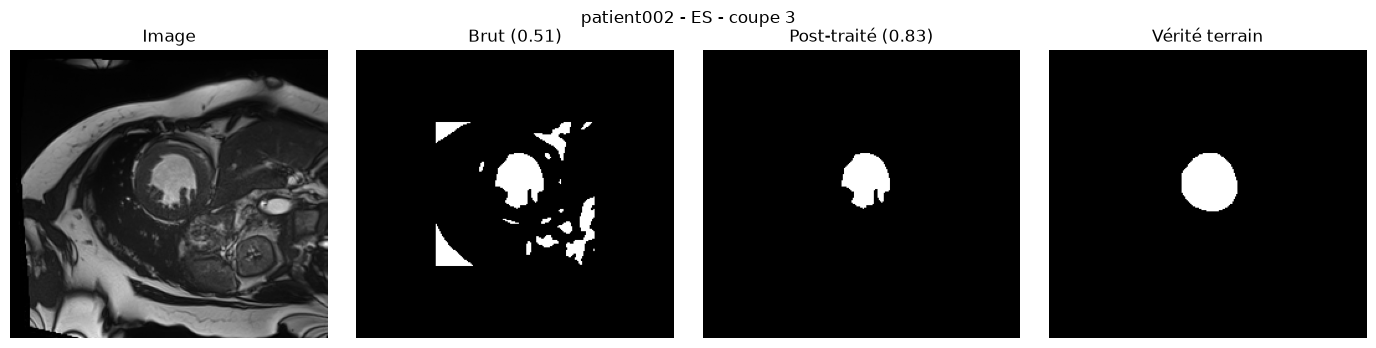

patient002 


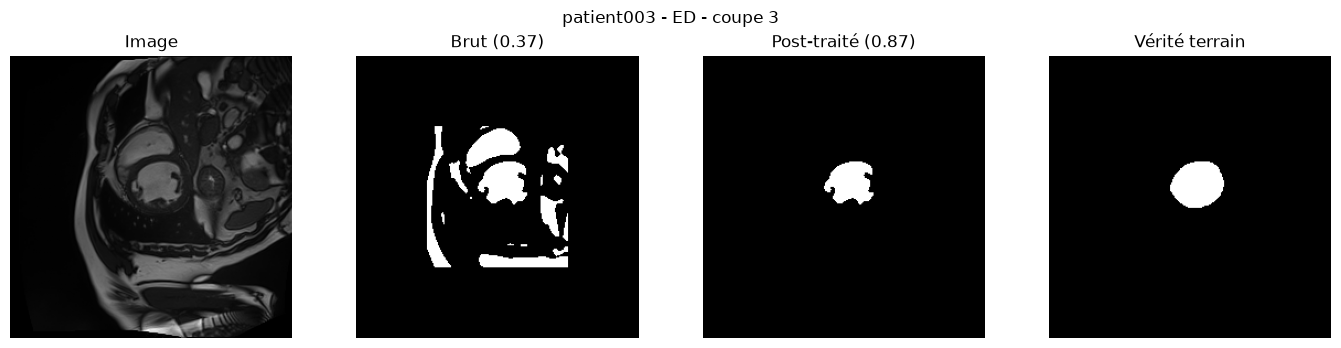

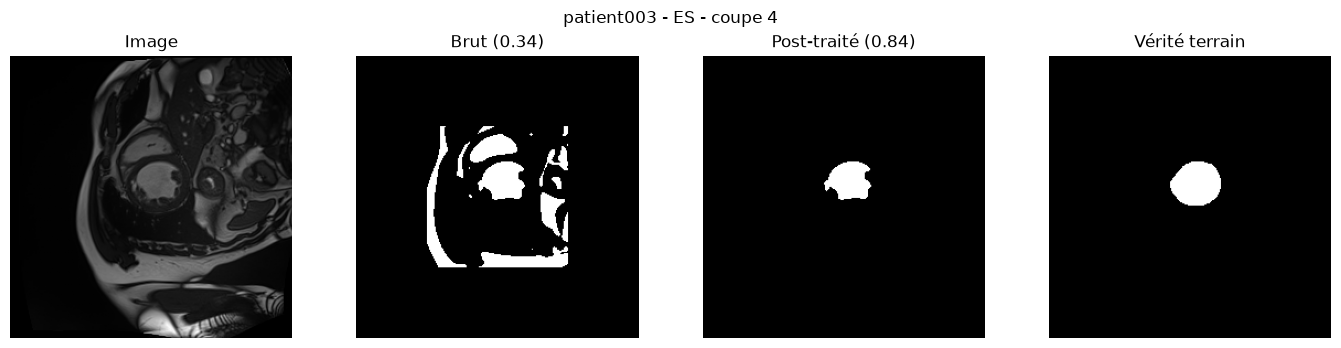

patient003 


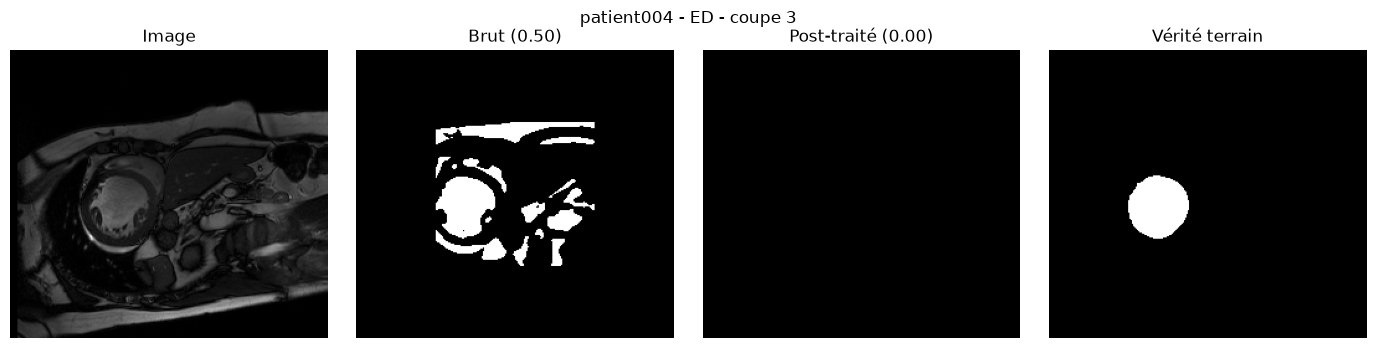

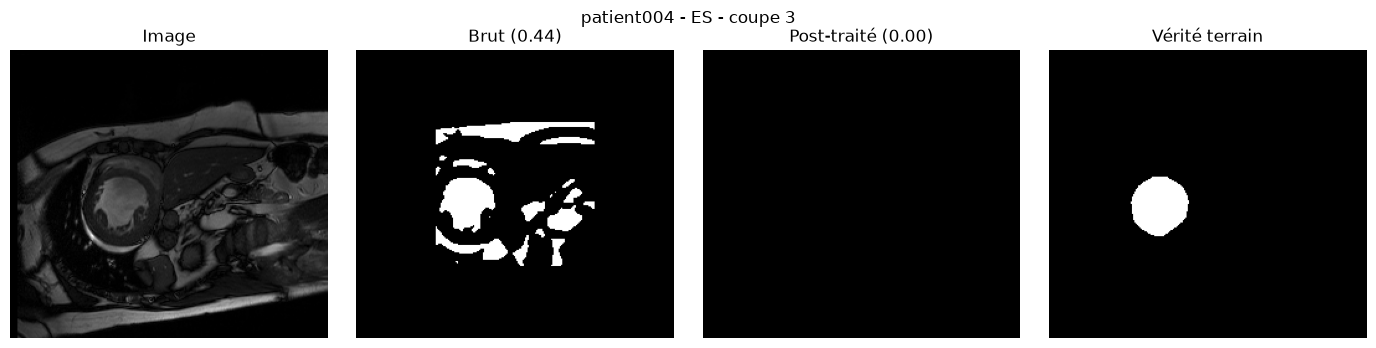

patient004 


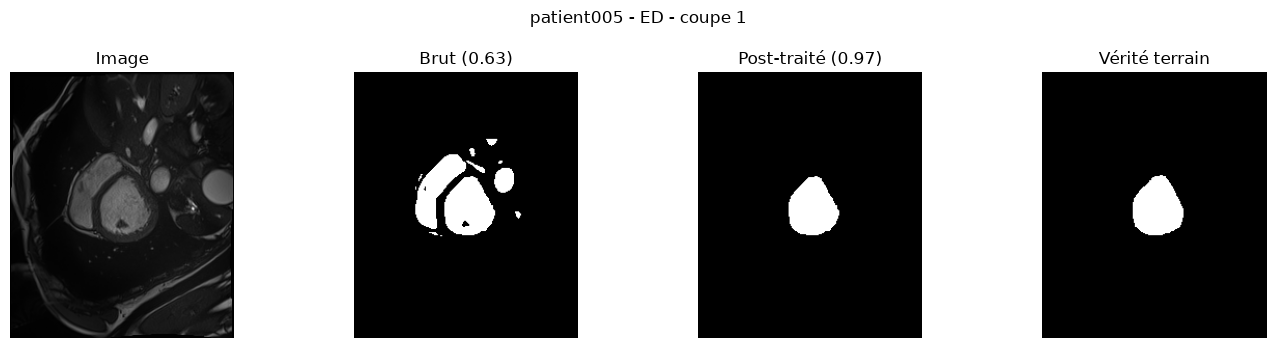

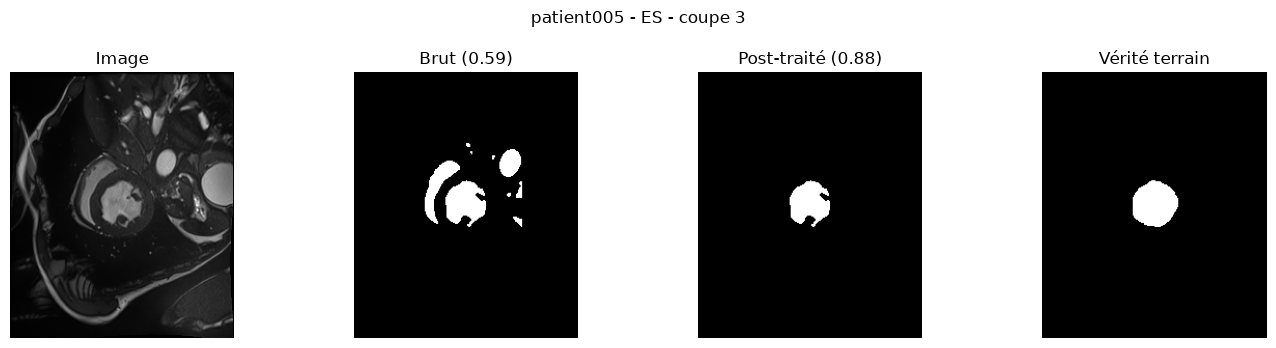

patient005 
patient006 
patient007 
patient008 
patient009 
patient010 
patient011 
patient012 
patient013 
patient014 
patient015 
patient016 
patient017 
patient018 
patient019 
patient020 
patient021 
patient022 
patient023 
patient024 
patient025 
patient026 
patient027 
patient028 
patient029 
patient030 
patient031 
patient032 
patient033 
patient034 
patient035 
patient036 
patient037 
patient038 
patient039 
patient040 
patient041 
patient042 
patient043 
patient044 
patient045 
patient046 
patient047 
patient048 
patient049 
patient050 
patient051 
patient052 
patient053 
patient054 
patient055 
patient056 
patient057 
patient058 
patient059 
patient060 
patient061 
patient062 
patient063 
patient064 
patient065 
patient066 
patient067 
patient068 
patient069 
patient070 
patient071 
patient072 
patient073 
patient074 
patient075 
patient076 
patient077 
patient078 
patient079 
patient080 
patient081 
patient082 
patient083 
patient084 
patient085 
patient086 
patient087 
pati

In [234]:
from scipy import ndimage as ndi
from skimage.measure import label, regionprops

#pt_dir = os.path.join(base_dir, "posttraitement")

base_dir = "Documents/ACDC/"
pt_dir = os.path.join(base_dir, "post_traitement_otsu")
os.makedirs(pt_dir, exist_ok=True)
os.makedirs(pt_dir, exist_ok=True)
N_AFFICHER = 4      # nb de patients affichés (ED et ES)
def dice(a, b):
    """Calcule le coefficient de Dice (mesure de similarité)"""
    return 2 * np.logical_and(a, b).sum() / (a.sum() + b.sum() + 1e-8)
def volume_ml(mask, nii_img):
    """Calcule le volume en mL à partir du masque et des voxels NIfTI"""
    vox_dim = nii_img.header.get_zooms()
    volume_mm3 = np.sum(mask) * (vox_dim[0] * vox_dim[1] * vox_dim[2])
    return volume_mm3 / 1000.0  # Conversion mm3 en mL

def post_traitement(m):
    """remplit les trous, garde la région (50-4000 px) la plus proche du centre"""
    m = ndi.binary_fill_holes(m)
    lab = label(m)
    H, W = m.shape
    regions = [r for r in regionprops(lab) if 50 <= r.area <= 4000]
    if not regions:
        return np.zeros(m.shape, np.uint8)
    r = min(regions, key=lambda r: np.hypot(r.centroid[0] - H/2, r.centroid[1] - W/2))
    return (lab == r.label).astype(np.uint8)
def pt_3d(vol):
    lab = label(vol, connectivity=3)
    if lab.max() == 0:
        return vol
    tailles = np.bincount(lab.ravel()); tailles[0] = 0
    return (lab == tailles.argmax()).astype(np.uint8)
    

res_pt = []
for i, p in enumerate(patient_folders):         
    pid = os.path.basename(p)
    info = read_info(p)

    for phase in ["ED", "ES"]:
        n = int(info[phase])
        gt_nii = nib.load(os.path.join(p, f"{pid}_frame{n:02d}_gt.nii.gz"))
        img    = nib.load(os.path.join(p, f"{pid}_frame{n:02d}.nii.gz")).get_fdata()
        gt     = gt_nii.get_fdata() == 3
        slices = [z for z in range(gt.shape[2]) if gt[:, :, z].any()]
        if not slices:
            continue

        # contour actif puis post-traitement
        brut = np.stack([seg_otsu(img[:, :, z]) for z in range(img.shape[2])], axis=2)
        propre = np.stack([post_traitement(brut[:, :, z]) for z in range(brut.shape[2])], axis=2)
        propre = pt_3d(propre)
        np.save(os.path.join(pt_dir, f"{pid}_{phase}.npy"), propre)

        # dice et erreur de volume
        d_avant = np.mean([dice(brut[:, :, z],   gt[:, :, z]) for z in slices])
        d_apres = np.mean([dice(propre[:, :, z], gt[:, :, z]) for z in slices])
        v_gt = volume_ml(gt, gt_nii)
        v_brut, v_propre = volume_ml(brut, gt_nii), volume_ml(propre, gt_nii)
        res_pt.append((pid, phase, d_avant, d_apres,
                       abs(v_brut - v_gt) / v_gt * 100,
                       abs(v_propre - v_gt) / v_gt * 100,
                       v_gt, v_propre))

        # affichage des N premiers patients (ED et ES)
        if i < N_AFFICHER:
            z = max(slices, key=lambda z: gt[:, :, z].sum())
            fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
            for a, (im, t) in zip(ax, [(img[:, :, z], "Image"),
                                       (brut[:, :, z],   f"Brut ({dice(brut[:, :, z], gt[:, :, z]):.2f})"),
                                       (propre[:, :, z], f"Post-traité ({dice(propre[:, :, z], gt[:, :, z]):.2f})"),
                                       (gt[:, :, z], "Vérité terrain")]):
                a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
            fig.suptitle(f"{pid} - {phase} - coupe {z}")
            plt.tight_layout(); plt.show()

    print(f"{pid} ")


In [235]:

df = pd.DataFrame(res_pt, columns=["patient", "phase", "dice_avant", "dice_apres","err_avant_%", "err_apres_%", "vol_GT_mL", "vol_propre_mL"])

df.to_csv(os.path.join(pt_dir, "resume_post_traitement.csv"), index=False)

print(df.groupby("phase")[["dice_avant", "dice_apres"]].mean().round(3))

print("\n erreur de volume (Médiane) ")
print(df.groupby("phase")[["err_avant_%", "err_apres_%"]].median().round(1))
print(f"Avant : {df['err_avant_%'].median():.0f}% | Après : {df['err_apres_%'].median():.0f}%")

       dice_avant  dice_apres
phase                        
ED          0.326       0.638
ES          0.206       0.430

 erreur de volume (Médiane) 
       err_avant_%  err_apres_%
phase                          
ED           380.9         21.4
ES           952.4         51.3
Avant : 521% | Après : 36%


## ==> la méthode d'Otsu est finalement retenue pour le post-traitement car elle surpasse les contours actifs en offrant un meilleur score Dice (notamment 0.638 en phase ED) et une réduction spectaculaire de l'erreur de volume, qui descend à 36 % en moyenne. ces performances garantissent une segmentation beaucoup plus fidèle de la cavité cardiaque et des mesures cliniques plus fiables pour l'analyse des pathologies.

# Unet

In [122]:
import sys
print(sys.version)
print(sys.executable)

3.12.7 (tags/v3.12.7:0b05ead, Oct  1 2024, 03:06:41) [MSC v.1941 64 bit (AMD64)]
C:\Users\Sorbonne\tf_env\Scripts\python.exe


In [123]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [ ]:
base_dir = "Documents/ACDC/"
data_dir = os.path.join(base_dir, "dataset")
unet_dir = os.path.join(base_dir, "unet")
os.makedirs(os.path.join(unet_dir, "predictions"), exist_ok=True)
os.makedirs(os.path.join(unet_dir, "comparaison"), exist_ok=True)


In [ ]:

T = 192  #  images IRM converties avant envoyées U-Net.
patient_folders = sorted(glob.glob(os.path.join(data_dir, "patient*")))

def vers_carre(vol):
    """
    ENTRÉE : volume 3D d'IRM (H, W, Z).
    SORTIE : volume en taille carrée (192, 192, Z).
    """
    H, W, Z = vol.shape
    out = np.zeros((T, T, Z), vol.dtype)
    ys, yd, h = max((H - T)//2, 0), max((T - H)//2, 0), min(H, T)
    xs, xd, w = max((W - T)//2, 0), max((T - W)//2, 0), min(W, T)
    out[yd:yd+h, xd:xd+w] = vol[ys:ys+h, xs:xs+w]
    return out

def normaliser(img):
    """
    ENTRÉE :image brute (pixels)
    SORTIE :image normalisée (moyenne à 0 et écart-type à 1 pour stabiliser l'apprentissage)
    """
    m, s = img.mean(axis=(0, 1), keepdims=True), img.std(axis=(0, 1), keepdims=True)
    return (img - m) / (s + 1e-8)

def charger_patient(p, phase):
    """
    ENTRÉE : patient (p) et la phase ("ED" ou "ES").
    SORTIE : mage IRM originale et le masque de vérité terrain binaire
    """
    pid = os.path.basename(p)
    info_path = os.path.join(p, "Info.cfg")
    info = {}
    with open(info_path, "r", encoding="utf-8") as f:
        for line in f:
            if ":" in line:
                k, v = line.split(":", 1)
                info[k.strip()] = v.strip()
    n = int(info[phase])
    img_path = os.path.join(p, f"{pid}_frame{n:02d}.nii.gz")
    gt_path = os.path.join(p, f"{pid}_frame{n:02d}_gt.nii.gz")
    img = nib.load(img_path).get_fdata().astype(np.float32)
    gt = nib.load(gt_path).get_fdata() == 3
    return img, gt

# séparation Train 80% / Validation20% 
rng = np.random.default_rng(42)
ordre = rng.permutation(len(patient_folders))
val_p = [patient_folders[i] for i in ordre[:20]]
train_p = [patient_folders[i] for i in ordre[20:]]

def construire_dataset(liste_patients):
    """
    ENTRÉE : liste  patients
    SORTIE : matrices X (images IRM traitées) et Y (masques de vérité terrain)
    """
    X, Y = [], []
    for p in liste_patients:
        for phase in ["ED", "ES"]:
            img, gt = charger_patient(p, phase)
            img_c = vers_carre(normaliser(img)).transpose(2, 0, 1)
            gt_c = vers_carre(gt.astype(np.float32)).transpose(2, 0, 1)
            X.append(img_c)
            Y.append(gt_c)
    return np.concatenate(X)[..., np.newaxis], np.concatenate(Y)[..., np.newaxis]

Xt, Yt = construire_dataset(train_p)#effective des datasets d'entraînement (Xt, Yt) et de validation (Xv, Yv)
Xv, Yv = construire_dataset(val_p)

def construire_unet(input_shape=(T, T, 1), f=16):
     """
    ENTRÉE : image  (192, 192, 1) et le nombre de filtres de base (16)
    SORTIE : modèle U-Net
    """
    inputs = layers.Input(input_shape)
    c1 = layers.Conv2D(f, 3, padding="same", activation="relu")(inputs)
    p1 = layers.MaxPooling2D()(c1)
    c2 = layers.Conv2D(f*2, 3, padding="same", activation="relu")(p1)
    p2 = layers.MaxPooling2D()(c2)
    cb = layers.Conv2D(f*4, 3, padding="same", activation="relu")(p2)
    u2 = layers.UpSampling2D()(cb)
    u2 = layers.concatenate([u2, c2])
    d2 = layers.Conv2D(f*2, 3, padding="same", activation="relu")(u2)
    u1 = layers.UpSampling2D()(d2)
    u1 = layers.concatenate([u1, c1])
    d1 = layers.Conv2D(f, 3, padding="same", activation="relu")(u1)
    outputs = layers.Conv2D(1, 1, activation="sigmoid")(d1)
    return models.Model(inputs, outputs)

def dice_loss(y_true, y_pred):
    """
    ENTRÉE :  vrai masque (y_true) et le masque prédit  (y_pred).
    SORTIE : valeur de la perte Dice (mesure l'erreur de superposition des zones)
    """
    y_true_f, y_pred_f = tf.reshape(y_true, [-1]), tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return 1 - (2. * intersection + 1e-6) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + 1e-6)

In [125]:

model = construire_unet()
model.compile(optimizer="adam", loss=dice_loss, metrics=["accuracy"])

checkpoint_path = os.path.join(unet_dir, "meilleur_modele.keras")
callbacks = [tf.keras.callbacks.ModelCheckpoint(checkpoint_path, save_best_only=True, monitor="val_loss")]#sauvegarder automatiquement le meilleur modèle pendant l'apprentissage

model.fit(Xt, Yt, batch_size=16, epochs=25, validation_data=(Xv, Yv), callbacks=callbacks) #lancer le modele d'apprentissage (entraînement sur les données Xt/Yt, validation sur Xv/Yv)

Epoch 1/25
96/96 ━━━━━━━━━━━━━━━━━━━━ 53s 530ms/step - accuracy: 0.9049 - loss: 0.7523 - val_accuracy: 0.9686 - val_loss: 0.7634
Epoch 2/25
96/96 ━━━━━━━━━━━━━━━━━━━━ 51s 530ms/step - accuracy: 0.9699 - loss: 0.6627 - val_accuracy: 0.9734 - val_loss: 0.7408
Epoch 3/25
96/96 ━━━━━━━━━━━━━━━━━━━━ 50s 525ms/step - accuracy: 0.9734 - loss: 0.6162 - val_accuracy: 0.9781 - val_loss: 0.6803
Epoch 4/25
96/96 ━━━━━━━━━━━━━━━━━━━━ 51s 532ms/step - accuracy: 0.9768 - loss: 0.5462 - val_accuracy: 0.9790 - val_loss: 0.6047
Epoch 5/25
96/96 ━━━━━━━━━━━━━━━━━━━━ 53s 553ms/step - accuracy: 0.9781 - loss: 0.5053 - val_accuracy: 0.9768 - val_loss: 0.5640
Epoch 6/25
96/96 ━━━━━━━━━━━━━━━━━━━━ 50s 525ms/step - accuracy: 0.9823 - loss: 0.4511 - val_accuracy: 0.9792 - val_loss: 0.5285
Epoch 7/25
96/96 ━━━━━━━━━━━━━━━━━━━━ 51s 529ms/step - accuracy: 0.9843 - loss: 0.4153 - val_accuracy: 0.9843 - val_loss: 0.4916
Epoch 8/25
96/96 ━━━━━━━━━━━━━━━━━━━━ 50s 526ms/step - accuracy: 0.9859 - loss: 0.3811 - val_accu

In [132]:
# Listes pour stocker les scores de tous les patients
scores_classique = []
scores_unet = []

for p in val_p:
    pid = os.path.basename(p)
    
    for phase in ["ED", "ES"]:
        # 1. Charger la vérité terrain
        _, gt = charger_patient(p, phase)
        
        # 2. Charger le masque classique
        f_classique = os.path.join(pt_dir, f"{pid}_{phase}.npy")
        classique = np.load(f_classique) > 0 if os.path.exists(f_classique) else np.zeros_like(gt)
        
        # 3. Charger le masque U-Net
        f_unet = os.path.join(unet_dir, "predictions", f"{pid}_{phase}.npy")
        unet_pred = np.load(f_unet) > 0 if os.path.exists(f_unet) else np.zeros_like(gt)
        
        # 4. Ajouter les scores calculés dans les listes
        scores_classique.append(dice_score(classique, gt))
        scores_unet.append(dice_score(unet_pred, gt))

# 5. Calculer et afficher les moyennes finales
moyenne_classique = np.mean(scores_classique)
moyenne_unet = np.mean(scores_unet)


print(f"moyenne Dice normale : {moyenne_classique:.3f}")
print(f"moyenne Dice U-Net : {moyenne_unet:.3f}")

moyenne Dice normale : 0.418
moyenne Dice U-Net : 0.700


# Compare Poste_traitement avec U net(deep learning) :

In [ ]:
base_dir = "Documents/ACDC/"
data_dir = os.path.join(base_dir, "dataset")
pt_dir   = os.path.join(base_dir, "posttraitement") 
unet_dir = os.path.join(base_dir, "unet")
pred_dir = os.path.join(unet_dir, "predictions")

In [ ]:
patient_folders = sorted(glob.glob(os.path.join(data_dir, "patient*")))
rng = np.random.default_rng(42)
ordre = rng.permutation(len(patient_folders))
val_p = [patient_folders[i] for i in ordre[:20]]

def charger_gt(p, phase):
    """
    ENTRÉE : patient (p) et phase cardiaque ("ED" ou "ES").
    SORTIE : masque de vérité terrain binaire.
    """
    pid = os.path.basename(p)
    info_path = os.path.join(p, "Info.cfg")
    
    info = {}
    with open(info_path, "r", encoding="utf-8") as f:
        for line in f:
            if ":" in line:
                k, v = line.split(":", 1)
                info[k.strip()] = v.strip()
                
    n = int(info[phase])
    gt_path = os.path.join(p, f"{pid}_frame{n:02d}_gt.nii.gz")
    gt = nib.load(gt_path).get_fdata() == 3
    return gt

,Méthode,Dice Score (F1),IoU (Jaccard),Sensibilité (Rappel),Spécificité,Précision
0,Classique,0.4527,0.2926,0.5626,0.9891,0.3788
1,U-Net,0.7790,0.6380,0.6989,0.9989,0.8797


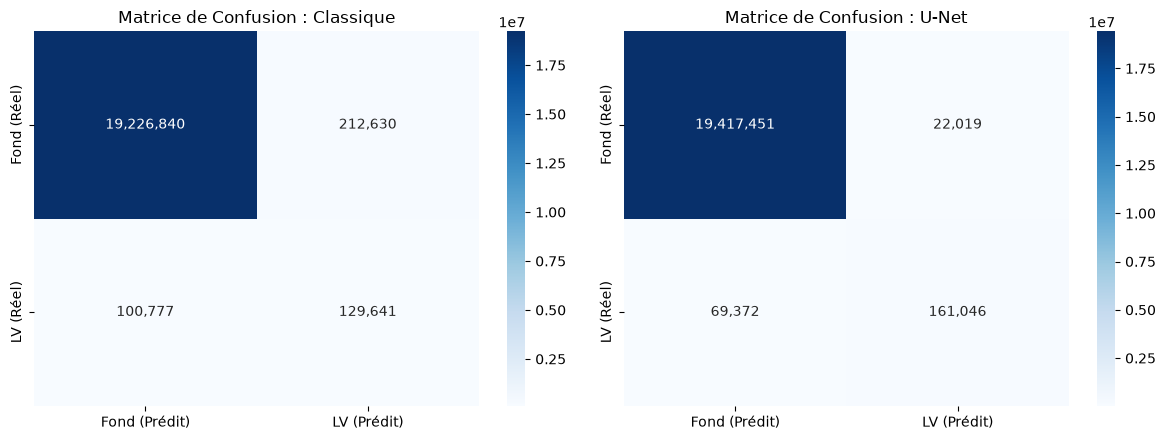

In [137]:
stats = { "Classique": {"TP": 0, "FP": 0, "TN": 0, "FN": 0},
    "U-Net":     {"TP": 0, "FP": 0, "TN": 0, "FN": 0}}

for p in val_p:
    pid = os.path.basename(p)
    for phase in ["ED", "ES"]:
        gt = charger_gt(p, phase).astype(bool)        
        # classique
        f_classique = os.path.join(pt_dir, f"{pid}_{phase}.npy")
        pred_classique = (np.load(f_classique) > 0) if os.path.exists(f_classique) else np.zeros_like(gt)        
        # U-Net
        f_unet = os.path.join(pred_dir, f"{pid}_{phase}.npy")
        pred_unet = (np.load(f_unet) > 0) if os.path.exists(f_unet) else np.zeros_like(gt)
        
        for nom, pred in [("Classique", pred_classique), ("U-Net", pred_unet)]:
            stats[nom]["TP"] += np.logical_and(pred, gt).sum()
            stats[nom]["FP"] += np.logical_and(pred, ~gt).sum()
            stats[nom]["TN"] += np.logical_and(~pred, ~gt).sum()
            stats[nom]["FN"] += np.logical_and(~pred, gt).sum()


tableau = []
for nom in ["Classique", "U-Net"]:
    tp, fp, tn, fn = stats[nom]["TP"], stats[nom]["FP"], stats[nom]["TN"], stats[nom]["FN"]
    
    dice = 2 * tp / (2 * tp + fp + fn + 1e-8)
    iou  = tp / (tp + fp + fn + 1e-8)
    sens = tp / (tp + fn + 1e-8)
    spec = tn / (tn + fp + 1e-8)
    prec = tp / (tp + fp + 1e-8)
    
    tableau.append({
        "Méthode": nom,
        "Dice Score (F1)": round(dice, 4),
        "IoU (Jaccard)": round(iou, 4),
        "Sensibilité (Rappel)": round(sens, 4),
        "Spécificité": round(spec, 4),
        "Précision": round(prec, 4)})

df_metrics = pd.DataFrame(tableau)
display(df_metrics)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, nom in zip(axes, ["Classique", "U-Net"]):
    cm = np.array([[stats[nom]["TN"], stats[nom]["FP"]],
                   [stats[nom]["FN"], stats[nom]["TP"]]])
    
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=ax,
                xticklabels=["Fond (Prédit)", "LV (Prédit)"],
                yticklabels=["Fond (Réel)", "LV (Réel)"])
    ax.set_title(f"Matrice de Confusion : {nom}")

plt.tight_layout()
plt.show()

## ==> U-Net obtient Dice de 0.78 (contre 0.45 pour la méthode classique), ce qui démontre une super-performance du Deep Learning pour le recouvrement exact de la zone cardiaque , aussi on a une faible précision (0.37) pour methode classsique , ce qui signifie qu'elle détectait beaucoup de bruit périphérique (fausses alertes) ,U-Net avec0.88 de précision, éliminant presque totalement les faux positifs tout en conservant une excellente spécificité (0.999)

# Mesure

In [174]:
base_dir = os.path.join("Documents", "ACDC")
data_dir = os.path.join(base_dir, "dataset")
unet_dir = os.path.join(base_dir, "unet")
pred_dir = os.path.join(unet_dir, "predictions")

In [176]:
#U-Net reçoit une image IRM et prédit un masque qui représente la région du ventricule gauche
import tensorflow as tf
checkpoint_path = os.path.join( unet_dir, "meilleur_modele.keras")
model = tf.keras.models.load_model(checkpoint_path,compile=False)


In [178]:
fichiers = glob.glob(os.path.join(pred_dir, "*.npy"))

patients = {os.path.basename(f).split("_")[0]for f in fichiers}
print("Nbr de masques :", len(fichiers))
print("Nbr de patients :", len(patients))

Nbr de masques : 200
Nbr de patients : 100


## Visualiser un masque

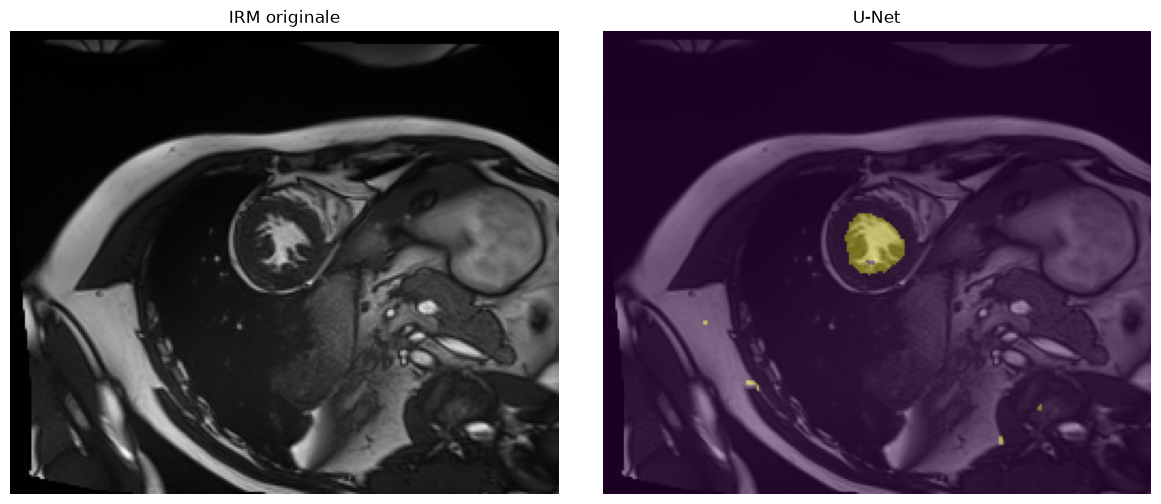

In [181]:
patient_id = "patient030"
phase = "ED"

p = os.path.join(data_dir, patient_id)

info = {}

with open(os.path.join(p, "Info.cfg"), encoding="utf-8") as f:
    for line in f:
        if ":" in line:
            k, v = line.split(":", 1)
            info[k.strip()] = v.strip()

frame = int(info[phase])

image_path = os.path.join( p, f"{patient_id}_frame{frame:02d}.nii.gz")
image = nib.load(image_path).get_fdata()
masque = np.load(os.path.join(pred_dir, f"{patient_id}_{phase}.npy"))

z = image.shape[2] // 2

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image[:, :, z], cmap="gray")
plt.title("IRM originale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image[:, :, z], cmap="gray")
plt.imshow(masque[:, :, z], alpha=0.4)
plt.title("U-Net")
plt.axis("off")

plt.tight_layout()
plt.show()

# Calculer les mesures cardiaques

In [183]:
resultats = []

for p in sorted(glob.glob(os.path.join(data_dir, "patient*"))):

    pid = os.path.basename(p)

    # Lire la classe et les phases ED/ES
    info = {}

    with open(os.path.join(p, "Info.cfg"), encoding="utf-8") as f:
        for ligne in f:
            if ":" in ligne:
                cle, valeur = ligne.split(":", 1)
                info[cle.strip()] = valeur.strip()

    volumes = {}

    for phase in ["ED", "ES"]:

        masque_path = os.path.join(pred_dir, f"{pid}_{phase}.npy")

        if not os.path.exists(masque_path):
            volumes[phase] = np.nan
            continue

        masque = np.load(masque_path).astype(bool)

        # Charger l'image IRM correspondante
        frame = int(info[phase])
        image_path = os.path.join(
            p, f"{pid}_frame{frame:02d}.nii.gz"
        )

        image = nib.load(image_path)

        if masque.shape != image.shape:
            print("Dimensions différentes :", pid, phase)
            volumes[phase] = np.nan
            continue

        # Calculer le volume du masque en mL
        voxel_ml = np.prod(image.header.get_zooms()[:3]) / 1000
        volumes[phase] = np.count_nonzero(masque) * voxel_ml

    edv = volumes["ED"]
    esv = volumes["ES"]

    # Calculer la fraction d'éjection
    if pd.notna(edv) and pd.notna(esv) and edv > 0:
        ef = (edv - esv) / edv * 100
    else:
        ef = np.nan

    resultats.append({
        "Patient": pid,
        "Classe": info.get("Group", "Inconnue"),
        "EDV_mL": edv,
        "ESV_mL": esv,
        "EF_pct": ef
    })

print("patients :", len(resultats))

patients : 100


In [184]:
df = pd.DataFrame(resultats)

print(df.round(2).to_string(index=False))

print("\nNbr de patients :", len(df))

mesures = ["EDV_mL", "ESV_mL", "EF_pct"]

print(
    "Mesures:",
    df[mesures].notna().all(axis=1).sum()
)

   Patient Classe  EDV_mL  ESV_mL  EF_pct
patient002    DCM  236.58  177.41   25.01
patient003    DCM  294.38  270.46    8.13
patient004    DCM  252.94  225.03   11.03
patient005    DCM  303.26  216.11   28.74
patient006    DCM  113.92  124.03   -8.87
patient007    DCM  316.23  282.34   10.72
patient008    DCM  221.51  195.02   11.96
patient009    DCM  272.27  242.83   10.81
patient010    DCM  328.44  285.99   12.93
patient011    DCM  201.41  189.67    5.83
patient012    DCM  317.26  268.29   15.44
patient013    DCM  281.69  202.23   28.21
patient014    DCM  268.96  233.09   13.34
patient015    DCM  163.07  116.30   28.68
patient016    DCM  415.90  372.96   10.33
patient017    DCM  366.41  328.32   10.39
patient018    DCM  199.11  168.57   15.34
patient019    DCM  363.64  291.47   19.85
patient020    DCM   43.63   36.68   15.93
patient021    HCM  208.53   81.51   60.91
patient022    HCM   78.01   38.94   50.09
patient023    HCM   64.51   20.20   68.69
patient024    HCM  106.23   25.49 

In [185]:
csv_path = os.path.join(base_dir, "mesures_unet.csv")

df.to_csv(csv_path, index=False)

print("Fichier enregistré :", csv_path)

Fichier enregistré : Documents\ACDC\mesures_unet.csv


In [186]:
print("valeurs manquantes :")
print(df[["EDV_mL", "ESV_mL", "EF_pct"]].isna().sum())

print("\npatients avec ESV supérieur à EDV :")
print(
    df.loc[
        df["ESV_mL"] > df["EDV_mL"],
        ["Patient", "EDV_mL", "ESV_mL", "EF_pct"]
    ]
)

print(df[["EDV_mL", "ESV_mL", "EF_pct"]].describe().round(2))

valeurs manquantes :
EDV_mL    0
ESV_mL    0
EF_pct    0
dtype: int64

patients avec ESV supérieur à EDV :
      Patient      EDV_mL      ESV_mL    EF_pct
4  patient006  113.924789  124.028778 -8.868999
       EDV_mL  ESV_mL  EF_pct
count  100.00  100.00  100.00
mean   161.48  101.55   41.46
std     76.46   76.46   20.20
min     30.83   15.29   -8.87
25%    107.77   51.16   28.33
50%    145.49   74.33   44.45
75%    199.76  137.30   54.32
max    415.90  372.96   80.48


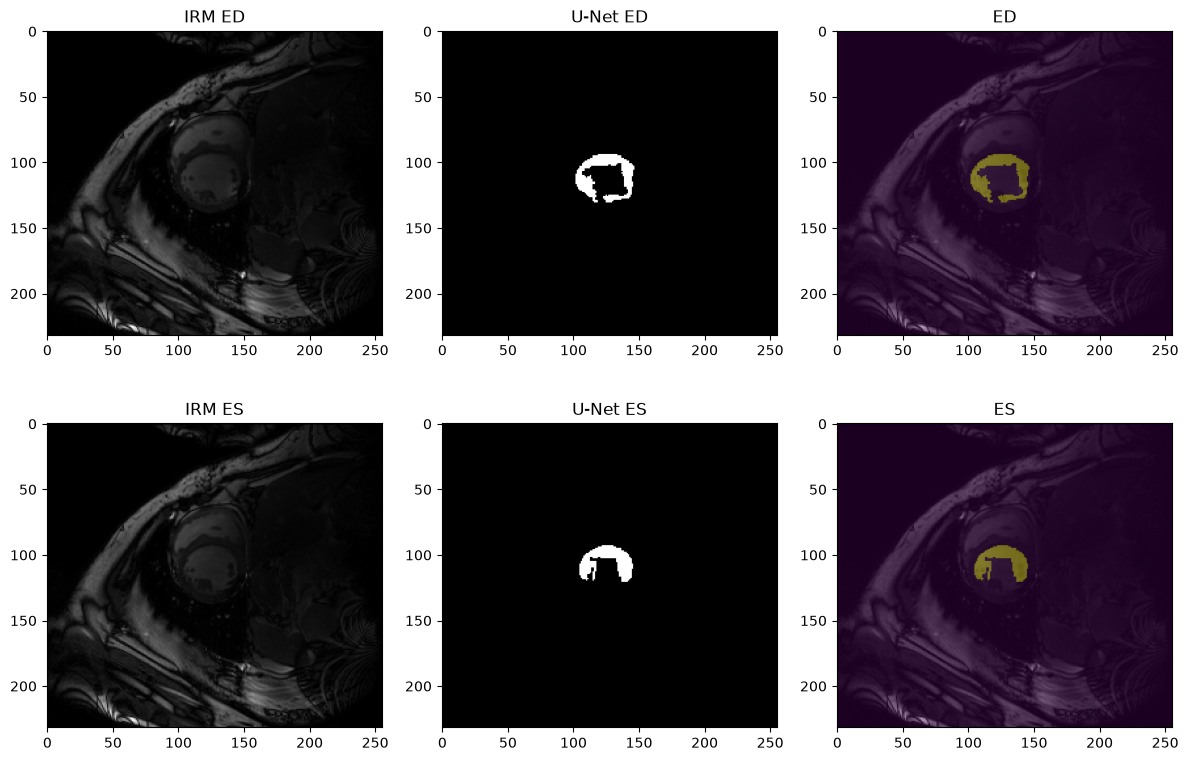

In [188]:
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

pid = "patient006"
p = os.path.join(data_dir, pid)

# Lire les numéros des images ED et ES
info = {}

with open(os.path.join(p, "Info.cfg"), encoding="utf-8") as f:
    for ligne in f:
        if ":" in ligne:
            cle, valeur = ligne.split(":", 1)
            info[cle.strip()] = valeur.strip()

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, phase in enumerate(["ED", "ES"]):

    frame = int(info[phase])

    image_path = os.path.join(
        p, f"{pid}_frame{frame:02d}.nii.gz"
    )

    image = nib.load(image_path).get_fdata()

    masque_path = os.path.join(
        pred_dir, f"{pid}_{phase}.npy"
    )

    masque = np.load(masque_path)

    # Coupe centrale
    z = image.shape[2] // 2

    axes[i, 0].imshow(image[:, :, z], cmap="gray")
    axes[i, 0].set_title(f"IRM {phase}")

    axes[i, 1].imshow(masque[:, :, z], cmap="gray")
    axes[i, 1].set_title(f"U-Net {phase}")

    axes[i, 2].imshow(image[:, :, z], cmap="gray")
    axes[i, 2].imshow(masque[:, :, z], alpha=0.4)
    axes[i, 2].set_title(f"{phase}")

plt.tight_layout()
plt.show()

# Classification : 

### U-Net entraîné sur 80 patients et validé sur 20 autres pour classification on utilise 20 qui pas utiliser dans unet 

In [190]:
patient_folders = sorted(glob.glob(os.path.join(data_dir, "patient*")))

rng = np.random.default_rng(42)
indices = np.arange(len(patient_folders))
rng.shuffle(indices)

val_p = [patient_folders[i] for i in indices[:20]]

patients_validation = {os.path.basename(p) for p in val_p}

df_test = df[df["Patient"].isin(patients_validation)].copy()

print("Nmbr de patients :", len(df_test))
print("\nrépartition des classes :")
print(df_test["Classe"].value_counts())

Nmbr de patients : 20

répartition des classes :
Classe
HCM     5
MINF    5
DCM     4
NOR     3
RV      3
Name: count, dtype: int64


## les features

In [191]:
features = ["EDV_mL", "ESV_mL", "EF_pct"]

df_test = df_test.dropna(subset=features + ["Classe"])

X = df_test[features]
y = df_test["Classe"]

print("Features :")
print(X.head())

print("\nClasses :")
print(y.head())

Features :
        EDV_mL      ESV_mL     EF_pct
2   252.940369  225.033188  11.033107
4   113.924789  124.028778  -8.868999
18   43.629332   36.677066  15.934844
21   64.506104   20.199936  68.685233
24  112.432480   52.748871  53.083957

Classes :
2     DCM
4     DCM
18    DCM
21    HCM
24    HCM
Name: Classe, dtype: str


In [197]:
features = ["EDV_mL", "ESV_mL", "EF_pct"]

# Garder les patients qui ont toutes les informations nécessaires
df_classif = df_test.dropna(
    subset=features + ["Classe"]
).copy()

X = df_classif[features]
y = df_classif["Classe"]
print("Nmbr de patients :", len(df_classif))
print("Features :", features)
print("classes:", sorted(y.unique()))

Nmbr de patients : 20
Features : ['EDV_mL', 'ESV_mL', 'EF_pct']
classes: ['DCM', 'HCM', 'MINF', 'NOR', 'RV']


In [198]:
modele = make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))

cv = StratifiedKFold(n_splits=3,shuffle=True,random_state=42)

# Prédire la classe de chaque patient
classes_predites = cross_val_predict(modele,X, y,cv=cv)

# construire un tableau avec les résultats
resultats = df_classif[["Patient", "Classe"]].copy()
resultats["Classe_predite"] = classes_predites
resultats["Correct"] = (resultats["Classe"] == resultats["Classe_predite"])

print(resultats.to_string(index=False))

   Patient Classe Classe_predite  Correct
patient004    DCM            DCM     True
patient006    DCM            DCM     True
patient020    DCM             RV    False
patient023    HCM            HCM     True
patient026    HCM           MINF    False
patient027    HCM            HCM     True
patient029    HCM            HCM     True
patient035    HCM            HCM     True
patient044   MINF           MINF     True
patient052   MINF             RV    False
patient053   MINF           MINF     True
patient054   MINF            HCM    False
patient058   MINF           MINF     True
patient061    NOR            HCM    False
patient063    NOR            HCM    False
patient073    NOR            HCM    False
patient083     RV             RV     True
patient094     RV             RV     True
patient099     RV           MINF    False
patient101    DCM            DCM     True


In [199]:
print( "Exactitude :",round(accuracy_score(y, classes_predites) * 100, 2), "%")

print("\n classification :")
print(classification_report(y,classes_predites,zero_division=0))

Exactitude : 60.0 %

 classification :
              precision    recall  f1-score   support

         DCM       1.00      0.75      0.86         4
         HCM       0.50      0.80      0.62         5
        MINF       0.60      0.60      0.60         5
         NOR       0.00      0.00      0.00         3
          RV       0.50      0.67      0.57         3

    accuracy                           0.60        20
   macro avg       0.52      0.56      0.53        20
weighted avg       0.55      0.60      0.56        20



In [201]:
resultats.to_csv(os.path.join(base_dir, "classes_predites.csv"),index=False)
print("résultats enregistrés dans classes_predites.csv")

résultats enregistrés dans classes_predites.csv


# Comparer les trois modèles :

In [207]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=3,shuffle=True,random_state=42)

modeles = {
    "Régression logistique": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    )
}

In [208]:
resultats = []

for nom, modele in modeles.items():

    scores = cross_validate(modele,X,y,cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1_macro": "f1_macro"
        }
    )

    resultats.append({
        "Modèle": nom,
        "Accuracy (%)": round(
            scores["test_accuracy"].mean() * 100, 2
        ),
        "Écart-type (%)": round(
            scores["test_accuracy"].std() * 100, 2
        ),
        "F1 macro (%)": round(
            scores["test_f1_macro"].mean() * 100, 2
        )
    })

comparaison = pd.DataFrame(resultats).sort_values("Accuracy (%)", ascending=False)

print(comparaison.to_string(index=False))

               Modèle  Accuracy (%)  Écart-type (%)  F1 macro (%)
Régression logistique         60.32           12.50         55.56
        Random Forest         39.68            4.49         35.33


# Matrice de confusion :

In [209]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

classes = ["DCM", "HCM", "MINF", "NOR", "RV"]

modele = modeles["Régression logistique"]

y_pred = cross_val_predict(modele,X,y,cv=cv)

print(classification_report(y,y_pred,labels=classes,zero_division=0))

              precision    recall  f1-score   support

         DCM       1.00      0.75      0.86         4
         HCM       0.50      0.80      0.62         5
        MINF       0.60      0.60      0.60         5
         NOR       0.00      0.00      0.00         3
          RV       0.50      0.67      0.57         3

    accuracy                           0.60        20
   macro avg       0.52      0.56      0.53        20
weighted avg       0.55      0.60      0.56        20



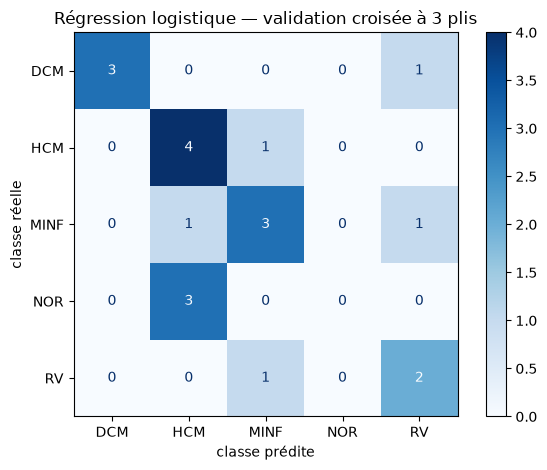

In [210]:
ConfusionMatrixDisplay.from_predictions(y,y_pred,labels=classes,display_labels=classes,cmap="Blues",values_format="d")

plt.xlabel("classe prédite")
plt.ylabel("classe réelle")
plt.title("Régression logistique — validation croisée à 3 plis")
plt.tight_layout()
plt.show()